# Практическое занятие 5. Разведочный анализ заказов

Цель: изучить данные о доставках, проверить качество целевой метки `late`, описать распределения и сравнить доли задержек. Исходные CSV находятся на два уровня выше папки `lb5`; исходные файлы не изменяются.

Для запуска выберите ядро **Python (lb5)** и выполните все ячейки по порядку после перезапуска ядра.

## 1. Загрузка и аудит исходных данных

Показываем размер сырой таблицы, типы полей и число пропусков по каждому полю.

In [44]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt

root = Path.cwd()
df = pd.read_csv('orders_dirty.csv')
dictionary = pd.read_csv('data_dictionary.csv')

print('Размер сырого набора N × p:', df.shape)
print('\nТипы полей:')
print(df.dtypes.to_string())
print('\nПропуски:')
print(df.isna().sum().to_string())

Размер сырого набора N × p: (600, 10)

Типы полей:
order_id                str
created_at              str
distance_km             str
queue_size          float64
weather                 str
zone                    str
promised_minutes      int64
actual_minutes        int64
late                  int64
vehicle_type            str

Пропуски:
order_id            0
created_at          0
distance_km         0
queue_size          1
weather             1
zone                0
promised_minutes    0
actual_minutes      0
late                0
vehicle_type        0


### 1.1. Полные дубликаты и проверка метки `late`

Метка должна равняться 1, если фактическое время превышает обещанное более чем на 15 минут. `actual_minutes` используется только для аудита.

In [45]:
dups = df.duplicated()
actual = pd.to_numeric(df['actual_minutes'], errors='coerce')
promised = pd.to_numeric(df['promised_minutes'], errors='coerce')
late = pd.to_numeric(df['late'], errors='coerce')
valid_audit = actual.notna() & promised.notna() & late.isin([0, 1])
conflict = valid_audit & ((actual - promised > 15).astype(int) != late)

print('Полных дублей:', int(dups.sum()))
print('Конфликтов late:', int(conflict.sum()))
print('Невалидных для аудита:', int((~valid_audit).sum()))
print(df.loc[dups | conflict,
             ['order_id', 'promised_minutes', 'actual_minutes', 'late']].to_string(index=False))

Полных дублей: 1
Конфликтов late: 1
Невалидных для аудита: 0
order_id  promised_minutes  actual_minutes  late
ORD-0035                68              71     1
ORD-0020                69              79     0


## 2. Аналитическая копия

Полный дубль и строка с конфликтной меткой исключаются из анализа. Исходный CSV сохраняется без изменений.

In [46]:
clean = df.loc[~dups & ~conflict].copy()
actions = pd.DataFrame([
    ['Сырой набор', 'Без изменений', len(df), len(df)],
    ['Удалить повторную строку', 'Полный дубль', len(df), len(df) - int(dups.sum())],
    ['Исключить конфликтную метку', 'late расходится с правилом >15 минут',
     len(df) - int(dups.sum()), len(clean)]
], columns=['Действие', 'Обоснование', 'N до', 'N после'])
print(actions.to_string(index=False))
print('\nРанние признаки: distance_km, queue_size, weather, zone, promised_minutes, vehicle_type.')
print('created_at — временная отметка; actual_minutes — только аудит; late — целевая метка.')

                   Действие                          Обоснование  N до  N после
                Сырой набор                        Без изменений   600      600
   Удалить повторную строку                         Полный дубль   600      599
Исключить конфликтную метку late расходится с правилом >15 минут   599      598

Ранние признаки: distance_km, queue_size, weather, zone, promised_minutes, vehicle_type.
created_at — временная отметка; actual_minutes — только аудит; late — целевая метка.


## 3. Описательная статистика числовых признаков

Для каждого признака указаны число корректных чисел `n`, пропуски и значения, которые не удалось преобразовать в число. Стандартное отклонение выборочное. Единицы: `distance_km` — км, `queue_size` — заказы, `promised_minutes` — минуты.

In [47]:
numeric = ['distance_km', 'queue_size', 'promised_minutes']
rows = []
for column in numeric:
    values = pd.to_numeric(clean[column], errors='coerce')
    rows.append({
        'Признак': column,
        'n': int(values.notna().sum()),
        'Пропуски': int(clean[column].isna().sum()),
        'Неконвертируемые': int(clean[column].notna().sum() - values.notna().sum()),
        'min': values.min(), 'max': values.max(),
        'mean': values.mean(), 'median': values.median(), 'std': values.std(),
        'Q1': values.quantile(.25), 'Q3': values.quantile(.75)
    })
stats = pd.DataFrame(rows)
print(stats.round(2).to_string(index=False))

         Признак   n  Пропуски  Неконвертируемые  min  max  mean  median   std   Q1    Q3
     distance_km 596         0                 2  1.0 52.8  9.11    8.75  5.31  4.6 13.12
      queue_size 597         1                 0  0.0 22.0 10.25    9.00  6.51  5.0 16.00
promised_minutes 598         0                 0 19.0 86.0 50.94   51.00 14.51 40.0 62.00


## 4. Задержки по погодным условиям

Знаменатель доли — число заказов с допустимой меткой `late` внутри группы. Отсутствующая категория показывается отдельно; результат для малой группы не следует обобщать.

In [48]:
clean['late_num'] = pd.to_numeric(clean['late'], errors='coerce')
groups = (clean.groupby('weather', dropna=False)
               .agg(N=('late_num', 'count'), N_late=('late_num', 'sum'))
               .reset_index())
groups['Доля, %'] = 100 * groups['N_late'] / groups['N']
print(groups.round(2).to_string(index=False))

weather   N  N_late  Доля, %
  clear 356     133    37.36
   rain 171      95    55.56
   snow  70      52    74.29
    NaN   1       0     0.00


## 5. Межквартильный размах и проверка необычных значений

Пороги 1,5 × IQR — статистическая эвристика. Сопоставляем их с учебным диапазоном словаря без автоматического удаления наблюдений.

In [49]:
distance = pd.to_numeric(clean['distance_km'], errors='coerce').dropna()
q1, q3 = distance.quantile([.25, .75])
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
numeric_distance = pd.to_numeric(clean['distance_km'], errors='coerce')
outliers = clean.loc[numeric_distance.lt(lower) | numeric_distance.gt(upper),
                     ['order_id', 'distance_km']]
print(f'Q1={q1:.2f}; Q3={q3:.2f}; IQR={iqr:.2f} км')
print(f'Пороги 1,5×IQR: [{lower:.2f}; {upper:.2f}] км')
print('Наблюдений вне порогов:', len(outliers))
print(outliers.to_string(index=False))
print('Словарь: обычно 0,5–20 км; 52,8 км требует проверки, но не автоудаления.')

Q1=4.60; Q3=13.12; IQR=8.53 км
Пороги 1,5×IQR: [-8.19; 25.91] км
Наблюдений вне порогов: 1
order_id distance_km
ORD-0073        52.8
Словарь: обычно 0,5–20 км; 52,8 км требует проверки, но не автоудаления.


## 6. Визуализация

Четыре графика создаются независимо и сохраняются как PNG в папку `lb5`. В подписях указаны единицы измерения и размер групп, где это требуется.

### 6.1. Гистограмма `distance_km`

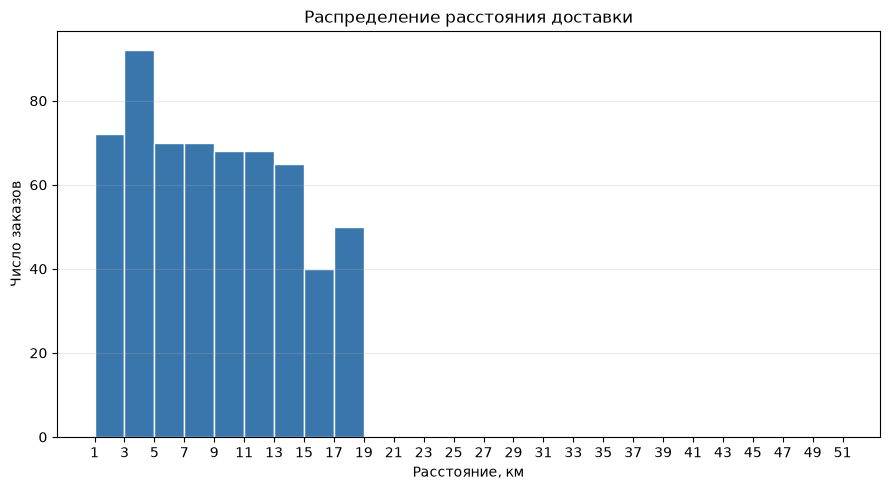

In [50]:
# Гистограмма расстояния доставки
distance = pd.to_numeric(clean['distance_km'], errors='coerce').dropna()
bins = [i for i in range(int(min(distance)), int(max(distance)), 2)]
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(distance, bins=bins, color='#3976ac', edgecolor='white')
ax.set(title='Распределение расстояния доставки',
       xlabel='Расстояние, км', ylabel='Число заказов')
ax.set_xticks(bins)
ax.grid(axis='y', alpha=.25)
fig.tight_layout()
fig.savefig(root / '01_hist.png', dpi=150)
plt.show()

**Наблюдение.** Распределение имеет правый хвост; максимальное расстояние заметно выше основной массы заказов.

### 6.2. Диаграмма размаха `distance_km`

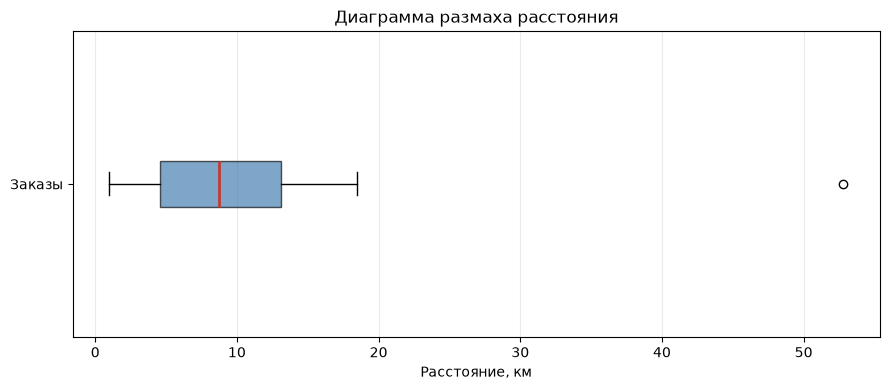

In [51]:
# Диаграмма размаха расстояния доставки
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot(distance, orientation='horizontal', patch_artist=True,
           boxprops={'facecolor': '#3976ac', 'alpha': .65},
           medianprops={'color': '#c23b32', 'linewidth': 2})
ax.set(title='Диаграмма размаха расстояния', xlabel='Расстояние, км')
ax.set_yticks([1], labels=['Заказы'])
ax.grid(axis='x', alpha=.25)
fig.tight_layout()
fig.savefig(root / '02_box.png', dpi=150)
plt.show()

**Наблюдение.** Медиана составляет около 8,75 км, а крайнее значение — 52,8 км. Статус аномалии проверяется ниже по IQR и словарю.

### 6.3. Число заказов по `late`

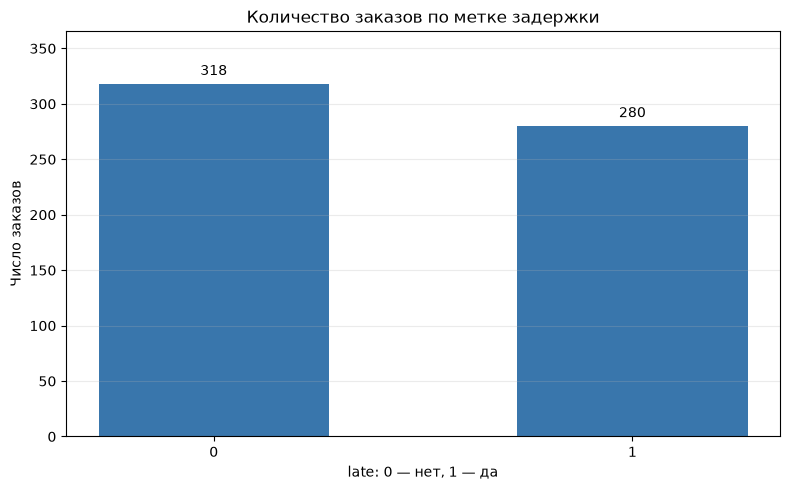

In [52]:
# Количество заказов по исторической метке late
late_counts = clean['late_num'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(late_counts.index.astype(int).astype(str), late_counts.values,
              color='#3976ac', width=.55)
ax.bar_label(bars, padding=4)
ax.set(title='Количество заказов по метке задержки',
       xlabel='late: 0 — нет, 1 — да', ylabel='Число заказов')
ax.set_ylim(0, late_counts.max() * 1.15)
ax.grid(axis='y', alpha=.25)
fig.tight_layout()
fig.savefig(root / '03_late.png', dpi=150)
plt.show()

**Наблюдение.** Число заказов с `late=1` немного меньше числа заказов с `late=0` в аналитической копии.

### 6.4. Доля `late=1` по `weather`

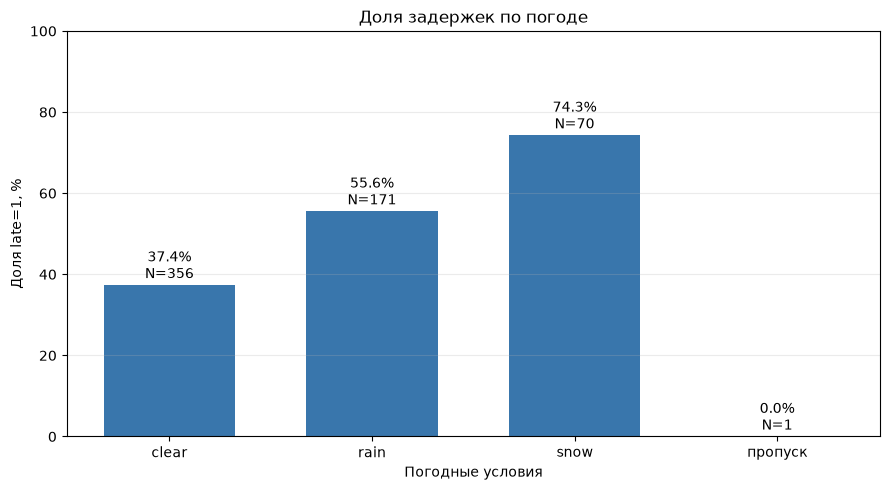

In [53]:
# Доля задержек по погоде с размером каждой группы
weather_labels = groups['weather'].fillna('пропуск').astype(str)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(weather_labels, groups['Доля, %'], color='#3976ac', width=.65)
for bar, share, group_size in zip(bars, groups['Доля, %'], groups['N']):
    ax.annotate(f'{share:.1f}%\nN={int(group_size)}',
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 5), textcoords='offset points', ha='center')
ax.set(title='Доля задержек по погоде',
       xlabel='Погодные условия', ylabel='Доля late=1, %', ylim=(0, 100))
ax.grid(axis='y', alpha=.25)
fig.tight_layout()
fig.savefig(root / '04_weather.png', dpi=150)
plt.show()

**Наблюдение.** Доли по категориям погоды различаются. Категория с пропущенной погодой содержит только один заказ; её долю нельзя интерпретировать как устойчивую оценку. Наблюдается предположительная корреляция: чем хуже погодные условия, тем чаще происходит задержка.

## 7. Выводы и ограничения

1. После исключения одного дубля и одной конфликтной метки осталось **598 из 600** заказов; `late=1` у **280 (46,8%)**.
2. Медианное расстояние — **8,75 км**, максимум — **52,8 км**. Одно наблюдение лежит за верхней границей **25,91 км** по IQR и требует проверки.
3. Доля задержек составляет **37,36%** при `clear`, **55,56%** при `rain` и **74,29%** при `snow`. Это описательная связь, а не доказательство влияния погоды.

**Ограничения.** Набор синтетический. Дефекты данных и малая численность некоторых групп ограничивают выводы; статистический выброс не равен ошибке.

**Следующий шаг.** Проверить первичную запись заказа с расстоянием 52,8 км и причины пропуска `weather`.